# Task 2: Improving a Data Visualization by telling a Data Story
 This notebook provides an analytical visualization on the Exploratory Data Analysis based on the goodreads-books dataset which includes data audits and visualization such as boxplots, histograms, heatmaps and tables. This is for IU Internationl University of Applied Sciences. Course: DLBDSEDAV01, Tutor: Prof Visieu Lac, Task 2, Matriculation Number: 102303641.

The link to original Exploratory Data Analysis: https://www.kaggle.com/code/artist03/exploratory-data-analysis <br>
The link to original Goodreads Dataset: https://www.kaggle.com/datasets/jealousleopard/goodreadsbooks

## Instructions for the executing this notebook

1. Install required packages if needed:
   `%conda install numpy pandas seaborn matplotlib kagglehub -y`
2. Run all cells from top to bottom.


In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import warnings
warnings.filterwarnings("ignore")



## 1. Accessing data 

This section accesses the dataset in csv file and initial data positioning while also setting up the pattern of decimal values .


In [3]:
try:
    path = kagglehub.dataset_download("jealousleopard/goodreadsbooks")
    csv_file = path + "/books.csv"
    data = pd.read_csv(csv_file, on_bad_lines='skip')
    pd.set_option('display.float_format', lambda x: '%.2f' % x)
except pd.errors.ParserError:
    pass

data.head()

,bookID,title,authors,average_rating,isbn,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,0439785960,9780439785969,eng,652,2095690,27591,9/16/2006,Scholastic Inc.
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,0439358078,9780439358071,eng,870,2153167,29221,9/1/2004,Scholastic Inc.
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,0439554896,9780439554893,eng,352,6333,244,11/1/2003,Scholastic
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,043965548X,9780439655484,eng,435,2339585,36325,5/1/2004,Scholastic Inc.
4,8,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,0439682584,9780439682589,eng,2690,41428,164,9/13/2004,Scholastic


## 2. Data Quality Inspection

This section summarizes basic structural properties of the dataset which includes dataset information and isolating structural anomalies like missingness and uniqueness or duplicate observations.


In [4]:
print("Essential Observations of the dataset:")
print('1. Dataset Shape:', data.shape)


Essential Observations of the dataset:
1. Dataset Shape: (11123, 12)


In [5]:
print('\n2. Dataset Information:')
data.info()


2. Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 11123 entries, 0 to 11122
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   bookID              11123 non-null  int64  
 1   title               11123 non-null  str    
 2   authors             11123 non-null  str    
 3   average_rating      11123 non-null  float64
 4   isbn                11123 non-null  str    
 5   isbn13              11123 non-null  int64  
 6   language_code       11123 non-null  str    
 7     num_pages         11123 non-null  int64  
 8   ratings_count       11123 non-null  int64  
 9   text_reviews_count  11123 non-null  int64  
 10  publication_date    11123 non-null  str    
 11  publisher           11123 non-null  str    
dtypes: float64(1), int64(5), str(6)
memory usage: 1.0 MB


In [6]:
print('\n3. Number of Unique Values:')
data.nunique()


3. Number of Unique Values:


bookID                11123
title                 10348
authors                6639
average_rating          209
isbn                  11123
isbn13                11123
language_code            27
  num_pages             997
ratings_count          5294
text_reviews_count     1822
publication_date       3679
publisher              2290
dtype: int64

In [7]:
data.columns = data.columns.str.strip()
missing_values = data.isnull().sum()

print("4. Missing Values:")
print(missing_values)

4. Missing Values:
bookID                0
title                 0
authors               0
average_rating        0
isbn                  0
isbn13                0
language_code         0
num_pages             0
ratings_count         0
text_reviews_count    0
publication_date      0
publisher             0
dtype: int64


In [8]:
duplicate_values = data.duplicated().sum()

print("5. Duplicate Values:")
print(duplicate_values)

5. Duplicate Values:
0


In [9]:
unique_values = data.nunique()
print("6. Unique Values:")
print(unique_values)


6. Unique Values:
bookID                11123
title                 10348
authors                6639
average_rating          209
isbn                  11123
isbn13                11123
language_code            27
num_pages               997
ratings_count          5294
text_reviews_count     1822
publication_date       3679
publisher              2290
dtype: int64


In [10]:
invalid_dates = data["publication_date"].isna().sum()
print("7. Invalid Dates:")
print(invalid_dates)

7. Invalid Dates:
0


In [11]:
date_range = data["publication_date"].agg(["min", "max"])
print("8. Date Range:")
print(date_range)

8. Date Range:
min    1/1/1900
max    9/9/2010
Name: publication_date, dtype: str


In [12]:
print("Total number of books:", data["num_pages"].count())


books_with_zero_pages = data["num_pages"] == 0
print("Total books with zero pages:", books_with_zero_pages.sum())


books_with_more_pages = data["num_pages"] > 0
print("Total books with more than zero pages:", books_with_more_pages.sum())

Total number of books: 11123
Total books with zero pages: 76
Total books with more than zero pages: 11047


## 3. Data and Structure Auditing

This section summarizes structural properties of the dataset which includes isolating structural anomalies like missingness and uniqueness or duplicate observations.


In [13]:
data = data[(data != 0).any(axis=1)]
data.count()

bookID                11123
title                 11123
authors               11123
average_rating        11123
isbn                  11123
isbn13                11123
language_code         11123
num_pages             11123
ratings_count         11123
text_reviews_count    11123
publication_date      11123
publisher             11123
dtype: int64

In [14]:
data= data[data['num_pages'] != 0]
data.count()

bookID                11047
title                 11047
authors               11047
average_rating        11047
isbn                  11047
isbn13                11047
language_code         11047
num_pages             11047
ratings_count         11047
text_reviews_count    11047
publication_date      11047
publisher             11047
dtype: int64

In [15]:
data["publication_date"] = pd.to_datetime(data["publication_date"], errors="coerce")
data["publication_year"] = data["publication_date"].dt.year
data["publication_year"] = data["publication_year"].fillna(0).astype(int)

data.head()

,bookID,title,authors,average_rating,isbn,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher,publication_year
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,0439785960,9780439785969,eng,652,2095690,27591,2006-09-16,Scholastic Inc.,2006
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,0439358078,9780439358071,eng,870,2153167,29221,2004-09-01,Scholastic Inc.,2004
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,0439554896,9780439554893,eng,352,6333,244,2003-11-01,Scholastic,2003
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,043965548X,9780439655484,eng,435,2339585,36325,2004-05-01,Scholastic Inc.,2004
4,8,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,0439682584,9780439682589,eng,2690,41428,164,2004-09-13,Scholastic,2004


In [16]:
data['bookID']= data['bookID'].astype(str)
data['isbn']= data['isbn'].astype(str)
data['isbn13']= data['isbn13'].astype(str)
data['publication_date']= data['publication_date'].astype(str)
data.rename(columns={'num_pages': 'number_of_pages'}, inplace=True)

data.head()

,bookID,title,authors,average_rating,isbn,isbn13,language_code,number_of_pages,ratings_count,text_reviews_count,publication_date,publisher,publication_year
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling/Mary GrandPré,4.57,0439785960,9780439785969,eng,652,2095690,27591,2006-09-16,Scholastic Inc.,2006
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling/Mary GrandPré,4.49,0439358078,9780439358071,eng,870,2153167,29221,2004-09-01,Scholastic Inc.,2004
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,0439554896,9780439554893,eng,352,6333,244,2003-11-01,Scholastic,2003
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling/Mary GrandPré,4.56,043965548X,9780439655484,eng,435,2339585,36325,2004-05-01,Scholastic Inc.,2004
4,8,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,0439682584,9780439682589,eng,2690,41428,164,2004-09-13,Scholastic,2004


In [17]:
print('\n Updated Dataset Information:')
data.info()


 Updated Dataset Information:
<class 'pandas.DataFrame'>
Index: 11047 entries, 0 to 11122
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   bookID              11047 non-null  str    
 1   title               11047 non-null  str    
 2   authors             11047 non-null  str    
 3   average_rating      11047 non-null  float64
 4   isbn                11047 non-null  str    
 5   isbn13              11047 non-null  str    
 6   language_code       11047 non-null  str    
 7   number_of_pages     11047 non-null  int64  
 8   ratings_count       11047 non-null  int64  
 9   text_reviews_count  11047 non-null  int64  
 10  publication_date    11045 non-null  str    
 11  publisher           11047 non-null  str    
 12  publication_year    11047 non-null  int64  
dtypes: float64(1), int64(4), str(8)
memory usage: 1.2 MB


## 4. Data Integrity

This section represents statistical description of the dataset which includes values points such as mean, median and many more along with plots that showcase observations with their potential outliers and distribution of average ratings.


In [18]:
colors = sns.color_palette("RdBu_r", 10)
sns.set_style("whitegrid")
os.makedirs("storytelling_plots", exist_ok=True)


In [19]:
numeric_data = data[['average_rating', 'number_of_pages', 'ratings_count', 'text_reviews_count']]
descriptive_stats = pd.concat([numeric_data.describe(),
                    numeric_data.describe().agg(["median", "skew"])])

print("Descriptive Statistics:")
print(descriptive_stats)



Descriptive Statistics:
        average_rating  number_of_pages  ratings_count  text_reviews_count
count         11047.00         11047.00       11047.00            11047.00
mean              3.93           338.72       18063.68              545.68
std               0.35           240.36      112875.94             2585.09
min               0.00             1.00           0.00                0.00
25%               3.77           196.00         109.00                9.00
50%               3.96           301.00         762.00               47.00
75%               4.13           416.00        5048.00              241.00
max               5.00          6576.00     4597666.00            94265.00
median            3.95           319.86        8047.50              393.34
skew              2.83             1.78           2.83                2.76


### Initial Understanding of Data:
Plot Visualization: Engagement measures are related to each other, but neither engagement nor book length is a reliable predictor of average rating. This means that the numerical measures are mostly weakly related and average rating cannot act as a predictor.

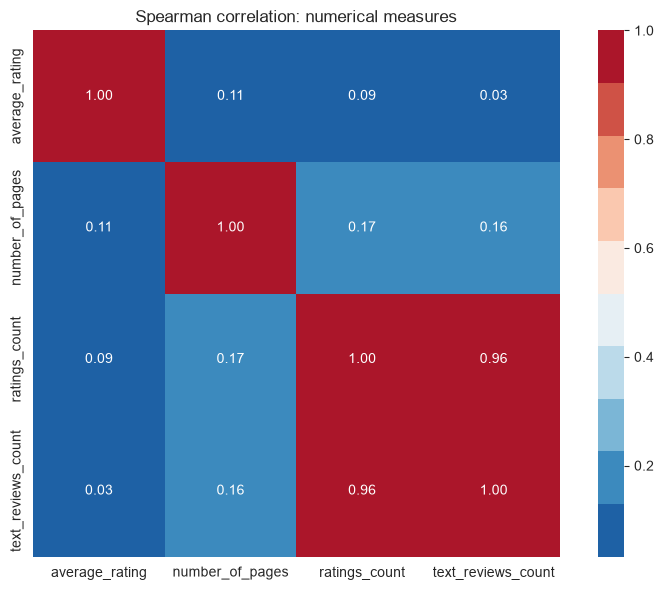

In [20]:
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_data.corr(method="spearman"), annot=True, fmt=".2f", cmap=colors, square=True)
plt.title("Spearman correlation: numerical measures")
plt.savefig("storytelling_plots/corr_heatmap.png", bbox_inches="tight")
plt.tight_layout()
plt.show()

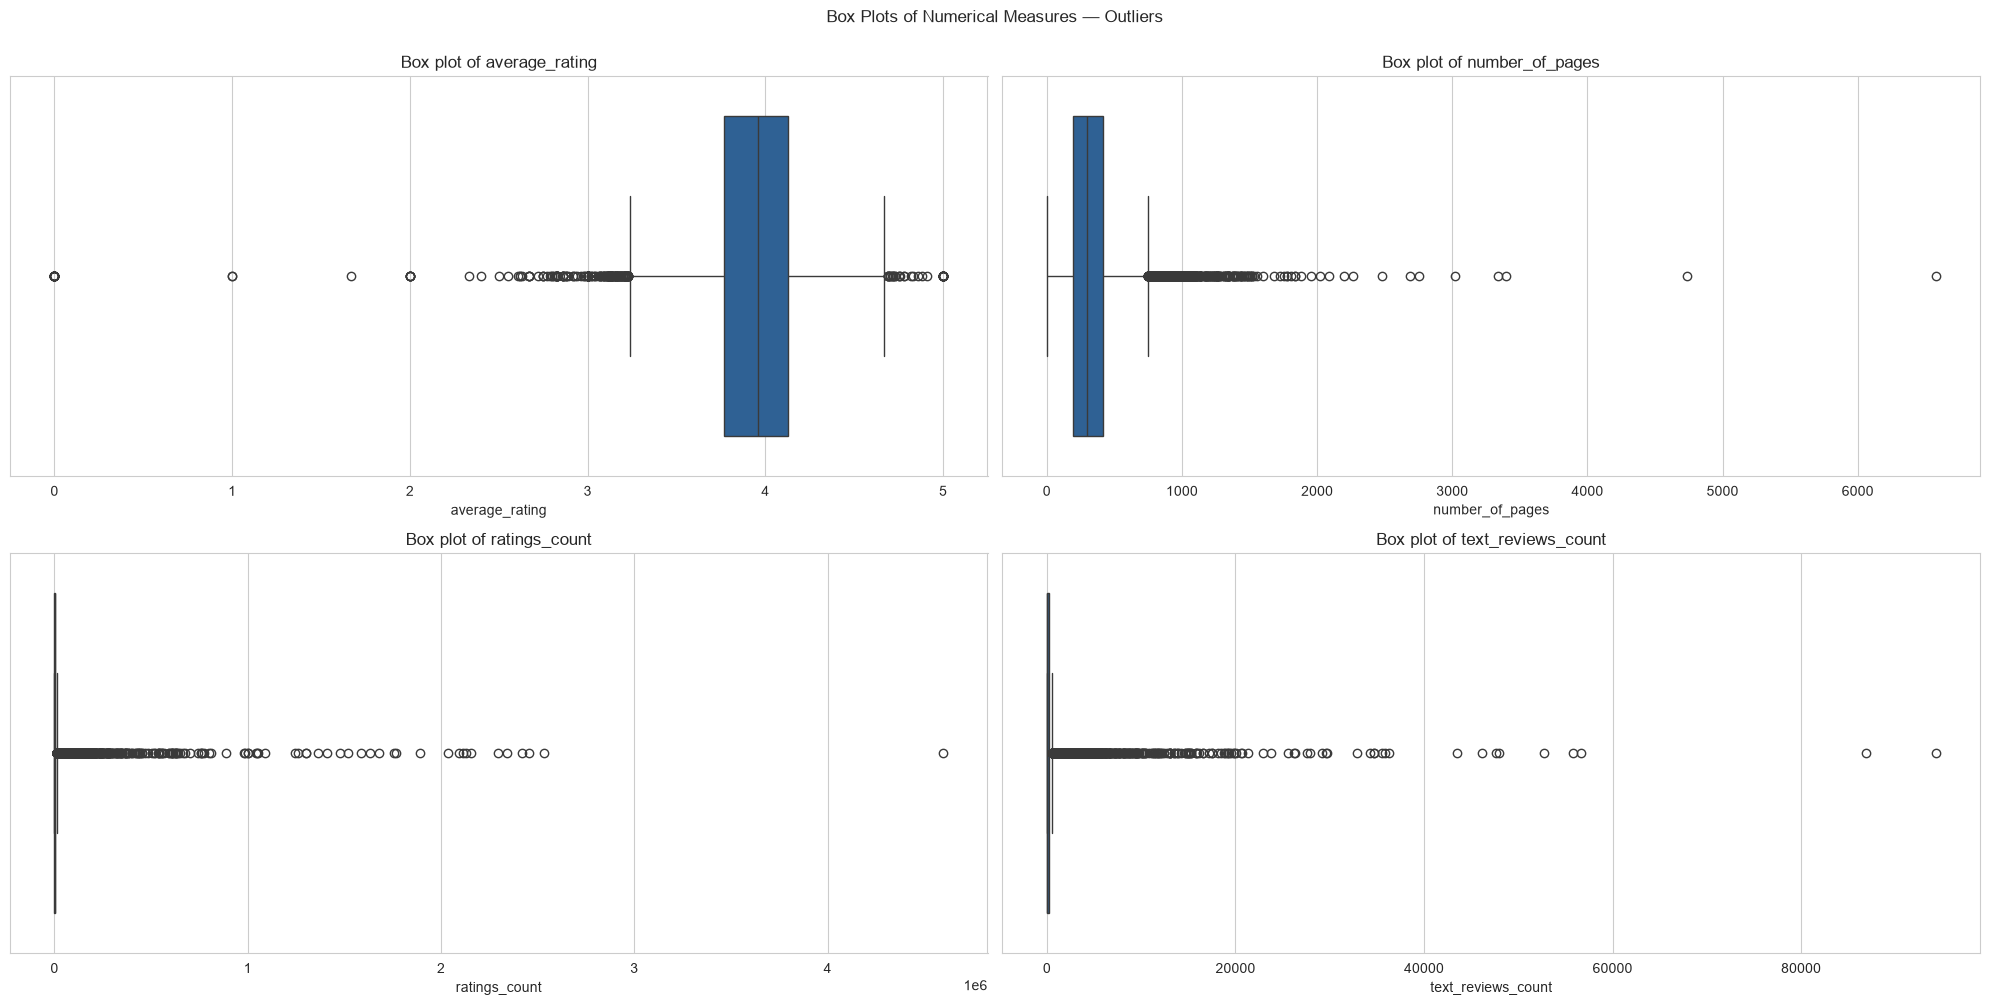

In [21]:
ncol = 2
nrow = int(np.ceil(len(numeric_data.columns) / ncol))
fig, axes = plt.subplots(nrows=nrow, ncols=ncol, figsize=(20, 10))
for i, col in enumerate(numeric_data.columns):
    row = i // ncol
    col_idx = i % ncol
    sns.boxplot(x=data[col], palette=colors, showfliers=True, ax=axes[row, col_idx], whis=1.5)
    axes[row, col_idx].set_title(f"Box plot of {col}")
    axes[row, col_idx].set_xlabel(col)
fig.suptitle("Box Plots of Numerical Measures — Outliers", y=1.00)

plt.savefig("storytelling_plots/box_plot_numerical_measures.png", bbox_inches="tight")
plt.tight_layout()
plt.show()

## 5. Data Storytelling: Redesigned Visualizations
This section mentions the different visualizations and plots and describes the story about these data-plots.

####  Redesigned Visualization 1:
<ul><li>Chart type: Scatter plot with Top 5 most-rated book annotations.<br></li>
<li>Story message: Books with the largest number of ratings are not necessarily the highest-rated books.</li></ul>

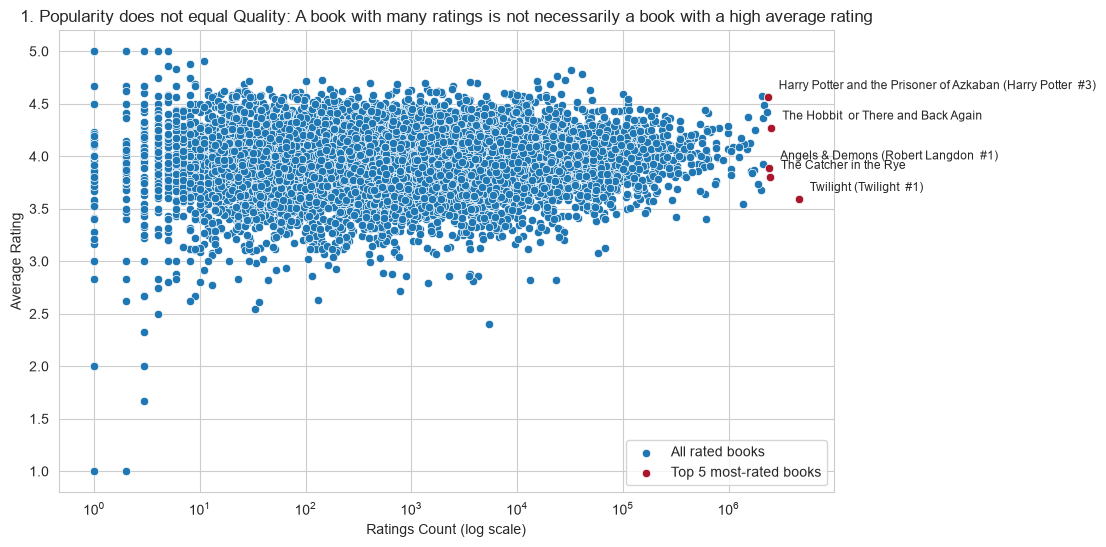

In [22]:
plt.figure(figsize=(10, 6))
plot_df = data[(data["ratings_count"] > 0) & (data["average_rating"].notna())].copy()
top_books = plot_df.nlargest(5, "ratings_count")


sns.scatterplot(data=plot_df, x="ratings_count", y="average_rating", label="All rated books", palette=colors)
sns.scatterplot(data=top_books, x="ratings_count", y="average_rating", label="Top 5 most-rated books", color="#AB162A")
label_books = top_books.head(5)
for _, row in label_books.iterrows():
    show_title = row["title"]
    plt.annotate(show_title,(row["ratings_count"], row["average_rating"]),xytext=(8, 6),textcoords="offset points",fontsize=8.5)


plt.legend(loc="lower right")
plt.xlabel("Ratings Count (log scale)")
plt.ylabel("Average Rating")
plt.title("1. Popularity does not equal Quality: A book with many ratings is not necessarily a book with a high average rating")
plt.xscale("log")
plt.savefig("storytelling_plots/ratings_count_vs_average_rating.png", bbox_inches="tight")

####  Redesigned Visualization 2:
<ul><li>Chart type: Histogram with mean and median reference lines, split into “all books” and “books with at least one rating.”<br></li>
<li>Story message: Goodreads ratings are strongly concentrated around 4 stars.</li></ul>

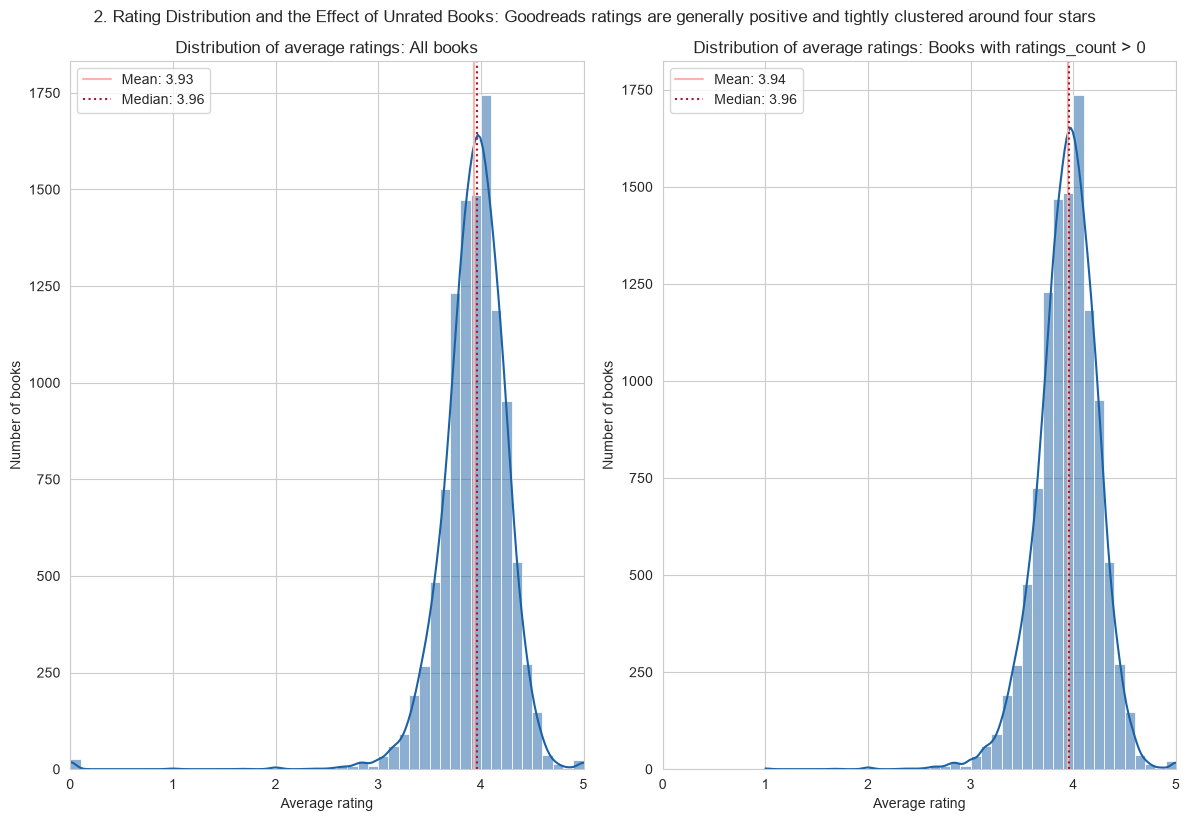

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 8))
bins = np.linspace(0, 5, 51)
rated = data.loc[data["ratings_count"] > 0, "average_rating"].dropna()
for ax, values, title in [(axes[0], data["average_rating"].dropna(), "All books"), (axes[1], rated, "Books with ratings_count > 0")]:
    sns.histplot(values, bins=bins, ax=ax, color="#1A61A5", kde=True)
    ax.axvline(values.mean(), color="#FAB3A9", linestyle="-", label=f"Mean: {values.mean():.2f}")
    ax.axvline(values.median(), color="#AB162A", linestyle=":", label=f"Median: {values.median():.2f}")
    ax.set(title=f"Distribution of average ratings: {title}", xlabel="Average rating", ylabel="Number of books", xlim=(0, 5))
    ax.legend()
plt.tight_layout()
fig.suptitle("2. Rating Distribution and the Effect of Unrated Books: Goodreads ratings are generally positive and tightly clustered around four stars", y=1.02)
plt.savefig("storytelling_plots/average_rating_distribution.png", bbox_inches="tight")
plt.show()

####  Redesigned Visualization 3:
<ul><li>Chart type: Violin plot showing the distribution of page counts across average-rating bands.<br></li>
<li>Story message: Longer books do not automatically receive better ratings.</li></ul>

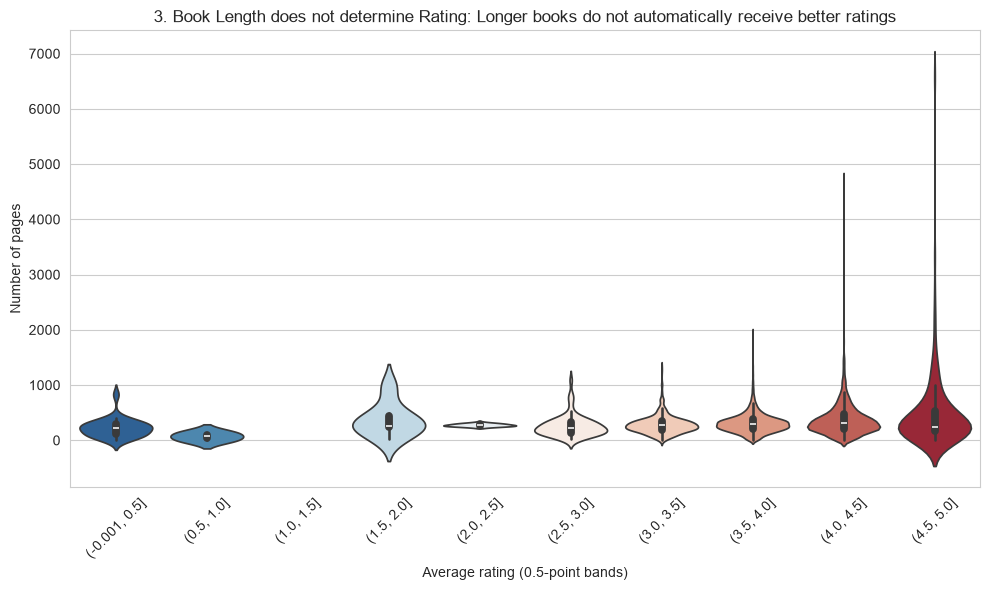

In [24]:
plt.figure(figsize=(10, 6))
plot_data = data[["average_rating", "number_of_pages"]].dropna().copy()
plot_data["rating_band"] = pd.cut(plot_data["average_rating"],bins=np.arange(0, 5.1, 0.5),include_lowest=True)

sns.violinplot(data=plot_data,x="rating_band", y="number_of_pages", palette=colors)
plt.xlabel("Average rating (0.5-point bands)")
plt.ylabel("Number of pages")
plt.title("3. Book Length does not determine Rating: Longer books do not automatically receive better ratings")
plt.savefig("storytelling_plots/book_length_and_ratings.png", bbox_inches="tight")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

####  Redesigned Visualization 4:
<ul><li>Chart type: Vertical bar plots showing the Top 10 languages and the Top 10 publishers.<br></li>
<li>Story message: The Goodreads dataset is heavily English-language focused.</li></ul>

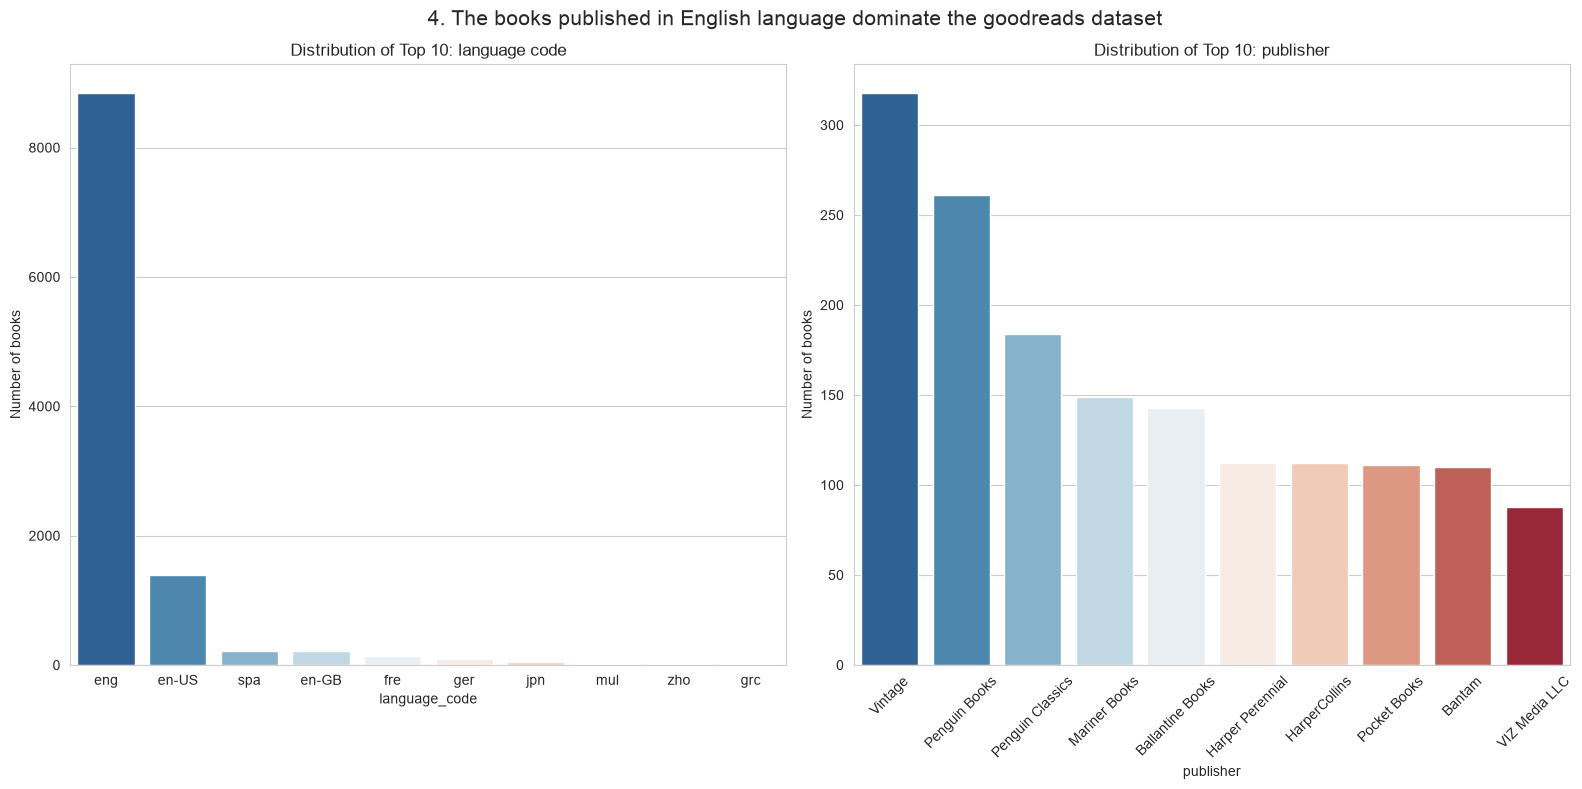

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
bins = np.linspace(0, 5, 51)
for ax, col, title in [(axes[0], "language_code", "language code"), (axes[1], "publisher", "publisher")]:
    counts = data[col].value_counts().head(10)
    sns.barplot(x=counts.index, y=counts.values, ax=ax, palette=colors)
    ax.set(title=f"Distribution of Top 10: {title}", ylabel="Number of books", xlabel=col)

plt.xticks(rotation=45)
fig.suptitle("4. The books published in English language dominate the goodreads dataset", fontsize=15)
plt.savefig("storytelling_plots/book_language_and_publisher.png", bbox_inches="tight")

plt.tight_layout()
plt.show()

####  Redesigned Visualization 5:
<ul><li>Chart type: Line plot with Top most-published books.<br></li>
<li>Story message: Publication Activity is concentrated in the year range 1996-2006.</li></ul>

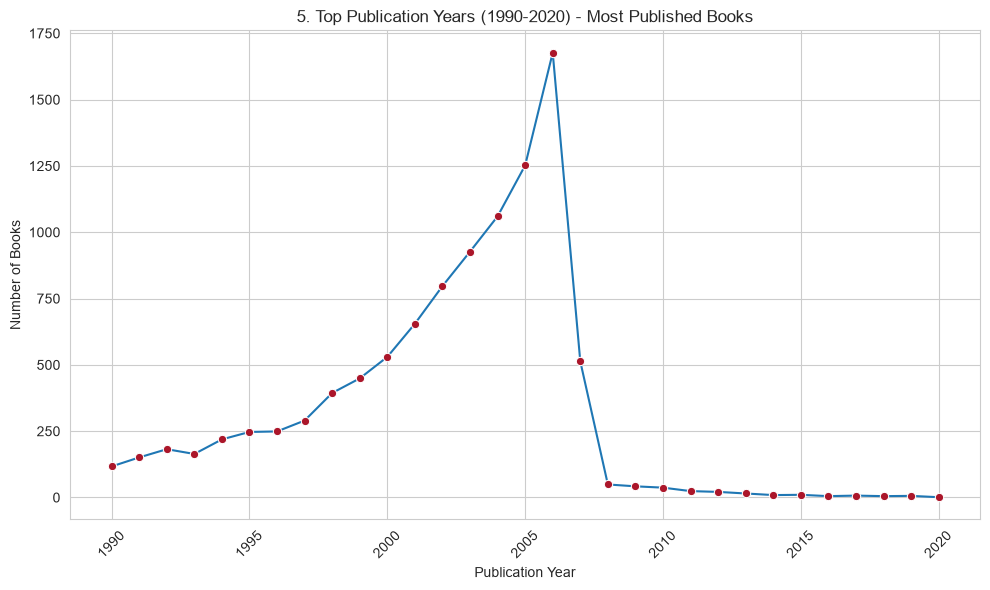

In [26]:
plt.figure(figsize=(10, 6))
demography = data[data["publication_year"].between(1990, 2020)].copy()

top_years = (demography["publication_year"].value_counts().nlargest(32).sort_index())
sns.lineplot(x=top_years.index, y=top_years.values, palette=colors, marker='o', markerfacecolor='#AB162A')
plt.title("5. Top Publication Years (1990-2020) - Most Published Books")
plt.xlabel("Publication Year")
plt.ylabel("Number of Books")
plt.savefig("storytelling_plots/top_publication_years.png", bbox_inches="tight")
plt.xticks(rotation=45)
plt.tight_layout()

## 6. Computed summary and modeling
This section summarizes the structural and data-wise basics of the dataset while also including ranking based values of books heavily influenced by the ratings and reviews.

In [39]:
summary = pd.Series({
    "Total number of books in the dataset": len(data),
    "Average-[mean] ratings of all books": data["average_rating"].mean(),
    "Average-[median] ratings of all books": data["average_rating"].median(),
    "Average-[mean] ratings of rated books": rated.mean(),
    "Books with zero ratings": data["ratings_count"].eq(0).sum(),
    "Average-[median] number of pages": data["number_of_pages"].median(),
    "Average-[median] count of ratings": data["ratings_count"].median(),
    "Average-[median] count of text reviews": data["text_reviews_count"].median()
}, name="")
print("Computed Summary:", summary.to_frame())

Computed Summary:                                                
Total number of books in the dataset   11047.00
Average-[mean] ratings of all books        3.93
Average-[median] ratings of all books      3.96
Average-[mean] ratings of rated books      3.94
Books with zero ratings                   79.00
Average-[median] number of pages         301.00
Average-[median] count of ratings        762.00
Average-[median] count of text reviews    47.00


#### Computed Data Modeling:
This mentions the basic computed data modeling that shows the top-most rated and least-rated books, books with least and most number of pages

In [40]:
print("The 10 books with the highest ratings:")
data.nsmallest(10, "average_rating")[["title", "authors", "average_rating", "ratings_count", "text_reviews_count", "publication_year", "number_of_pages"]]

The 10 books with the highest ratings:


,title,authors,average_rating,ratings_count,text_reviews_count,publication_year,number_of_pages
265,Out to Eat London 2002 (Lonely Planet Out to Eat),Lonely Planet/Mark Honan,0.00,0,0,2001,295
375,Juiced Official Strategy Guide,Doug Walsh,0.00,0,0,2005,112
987,Open City 6: The Only Woman He Ever Left,Open City Magazine/James Purdy/Daniel Pinchbec...,0.00,0,0,2000,200
2532,How To Meditate: An Anthology Of Talks On Medi...,Frederick P. Lenz,0.00,0,0,2004,228
2533,Insights: Talks On The Nature Of Existence,Frederick P. Lenz,0.00,0,0,2003,304
2758,Venac sonetnih venaca; Puževa srma,Dobrica Erić,0.00,0,0,1996,222
3492,Brodie's notes on Aldous Huxley's brave new world,Graham Handley,0.00,0,0,1992,71
4241,American Film Guide,Frank N. Magill,0.00,0,0,1983,5
4677,The Man and the Author: John Milton: Twentieth...,J. Martin Evans,0.00,0,0,2002,386
5323,Canopy: A Work for Voice and Light in Harvard ...,David Ward/Parveen Adams/Seamus Heaney/Ivan ...,0.00,0,0,1997,63


In [28]:
print("The 10 books with the highest ratings:")
data.nlargest(10, "average_rating")[["title", "authors", "average_rating", "ratings_count", "text_reviews_count", "publication_year", "number_of_pages"]]


The 10 books with the highest ratings:


,title,authors,average_rating,ratings_count,text_reviews_count,publication_year,number_of_pages
624,Comoediae 1: Acharenses/Equites/Nubes/Vespae/P...,Aristophanes/F.W. Hall/W.M. Geldart,5.00,0,0,1922,364
786,Willem de Kooning: Late Paintings,Julie Sylvester/David Sylvester,5.00,1,0,2006,83
855,Literature Circle Guide: Bridge to Terabithia:...,Tara MacCarthy,5.00,4,1,2002,32
1243,Middlesex Borough (Images of America: New Jersey),Middlesex Borough Heritage Committee,5.00,2,0,2003,128
4125,Zone of the Enders: The 2nd Runner Official St...,Tim Bogenn,5.00,2,0,2003,128
4788,The Diamond Color Meditation: Color Pathway to...,John Diamond,5.00,5,3,2006,74
4933,Bulgakov's the Master and Margarita: The Text ...,Elena N. Mahlow,5.00,4,0,1975,202
5023,The Complete Theory Fun Factory: Music Theory ...,Ian Martin/Katie Elliott,5.00,1,0,2004,96
5474,The Goon Show Volume 4: My Knees Have Fallen ...,NOT A BOOK,5.00,3,0,1996,2
5476,The Goon Show Volume 11: He's Fallen in the W...,NOT A BOOK,5.00,2,0,1995,2


In [29]:
print("The 10 books with the fewest number of pages:")
data.nsmallest(20, "number_of_pages")[["title", "authors", "average_rating", "ratings_count", "text_reviews_count", "publication_year", "number_of_pages"]]


The 10 books with the fewest number of pages:


,title,authors,average_rating,ratings_count,text_reviews_count,publication_year,number_of_pages
3454,Essential Welty: Why I Live at the P.O. A Mem...,Eudora Welty,3.94,92,28,2006,1
4270,The Return of the King (The Lord of the Rings ...,Brian Sibley/J.R.R. Tolkien,4.35,17,3,2002,1
4944,Lobsters,Charles Stross/Shandra Marie/Jared Doreck,3.83,158,5,2005,1
4945,Antibodies,Charles Stross/Shandra Marie/Jared Doreck,3.46,67,4,2005,1
5650,Meditations for Manifesting: Morning and Eveni...,Wayne W. Dyer,4.02,338,12,1995,1
5755,The Best American Mystery Stories 2003,Michael Connelly/Otto Penzler,3.60,5,2,2003,1
5779,The Best American Mystery Stories 2002,James Ellroy/Otto Penzler/John Biguenet/Michae...,3.58,0,0,2002,1
5944,The Neil Gaiman Audio Collection,Neil Gaiman,4.24,1666,208,2004,1
8505,LT's Theory of Pets,Stephen King,3.69,2824,140,2001,1
9036,There Was a Cold Lady Who Swallowed Some Snow!,Lucille Colandro/Jared Lee/Skip Hinnant,3.85,14,1,2006,1


In [30]:
print("The 10 books with the highest number of pages:")
data.nlargest(10, "number_of_pages")[["title", "authors", "average_rating", "ratings_count", "text_reviews_count", "publication_year", "number_of_pages"]]


The 10 books with the highest number of pages:


,title,authors,average_rating,ratings_count,text_reviews_count,publication_year,number_of_pages
6497,The Complete Aubrey/Maturin Novels (5 Volumes),Patrick O'Brian,4.70,1338,81,2004,6576
6802,The Second World War,Winston S. Churchill/John Keegan,4.45,1493,99,1986,4736
10906,Remembrance of Things Past (Boxed Set),Marcel Proust/C.K. Scott Moncrieff/Frederick A...,4.34,6,1,1981,3400
6,Harry Potter Collection (Harry Potter #1-6),J.K. Rowling,4.73,28242,808,2005,3342
6822,Summa Theologica 5 Vols,Thomas Aquinas,4.12,2734,84,1981,3020
7862,Harrison's Principles of Internal Medicine,Dennis L. Kasper/Dan L. Longo/Stephen L. Hause...,4.35,23,4,2004,2751
4,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling/Mary GrandPré,4.78,41428,164,2004,2690
10749,The Sword of Truth Boxed Set I: Wizard's Firs...,Terry Goodkind,4.29,4196,81,1998,2480
6257,The J.R.R. Tolkien Companion and Guide,Christina Scull/Wayne G. Hammond,4.64,45,0,2006,2264
5614,Study Bible: NIV,Anonymous,4.70,4166,186,2002,2198
